# 02 Exploratory data analysis (S3)

**Owner:** Sumaiya · **Due:** CP2 · **Covers:** proposal feedback FB2, Lec 3–5

**Data:** `load_table()`, 546,340 normal orders of at most 180 min (built in `01_data_audit`). Target:
`delivery_min`.

**[report]** and **[slides]** figures are saved to `figures/eda/` (PDF + 300-dpi PNG). **[notebook]** checks end
up as a sentence in the report, not a figure.

In [1]:
import sys; sys.path.insert(0, "..")   # so `common` imports work from notebooks/
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from common.data import load_table

t = load_table()
t["gap_min"] = t["delivery_min"] - t["promise_min"]       # actual - promised; describes the data only, never an input
t["late"] = t["gap_min"] > 0
print(f"{len(t):,} orders")

FIG_DIR = Path("../figures/eda"); FIG_DIR.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE = "#2a78d6", "#eb6834"      # team palette (presentation/outline.md): blue = ours, orange = platform
INK, MUTED, GREY, LIGHT, GRID = "#1f1f1f", "#6b6b6b", "#9a9a9a", "#d9d9d9", "#e6e6e6"
COL1, COL2 = 3.5, 7.16                  # IEEE one column / full page width (inches)
plt.rcParams.update({"font.size": 8, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titlesize": 9, "pdf.fonttype": 42,
                     "font.family": "DejaVu Sans"})


def save(fig, name):
    """PDF for the report, 300-dpi PNG for the slides."""
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")


def grid(ax, axis="y"):
    ax.grid(axis=axis, color=GRID, lw=0.6); ax.set_axisbelow(True)

546,340 orders


## 1. The target: centre, spread and shape (Lec 3) [notebook]
Two bin widths and a `log1p` version, for the log-target decision. Not exported; the report just states the skew.

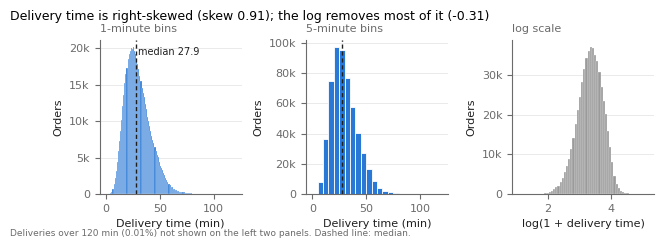

mean 29.6, median 27.9, sd 12.0, 90th 45.8, 99th 63.2
skew raw 0.91, log1p -0.31, share > 120 min 0.01%


In [2]:
d = t["delivery_min"]
fig, axes = plt.subplots(1, 3, figsize=(COL2, 2.0))
for ax, w in zip(axes[:2], (1, 5)):
    ax.hist(d, bins=np.arange(0, 121, w), color=BLUE, edgecolor="white", lw=0.2 if w == 1 else 0.6)
    ax.axvline(d.median(), color=INK, lw=1, ls=(0, (3, 2)))
    ax.set_xlabel("Delivery time (min)"); ax.set_title(f"{w}-minute bins", fontsize=8, color=MUTED)
axes[0].text(d.median() + 2, axes[0].get_ylim()[1] * 0.9, f"median {d.median():.1f}", fontsize=7, color=INK)
axes[2].hist(np.log1p(d), bins=60, color=GREY, edgecolor="white", lw=0.2)
axes[2].set_xlabel("log(1 + delivery time)"); axes[2].set_title("log scale", fontsize=8, color=MUTED)
for ax in axes:
    ax.set_ylabel("Orders"); grid(ax)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k" if v else "0"))
fig.subplots_adjust(wspace=0.45)
fig.suptitle(f"Delivery time is right-skewed (skew {d.skew():.2f}); the log removes most of it ({np.log1p(d).skew():.2f})",
             x=0.0, ha="left", fontsize=9, y=1.03)
fig.text(0.0, -0.1, f"Deliveries over 120 min ({(d > 120).mean():.2%}) not shown on the left two panels. Dashed line: median.",
         fontsize=6.5, color=MUTED)
plt.show()
print(f"mean {d.mean():.1f}, median {d.median():.1f}, sd {d.std():.1f}, 90th {d.quantile(.9):.1f}, 99th {d.quantile(.99):.1f}")
print(f"skew raw {d.skew():.2f}, log1p {np.log1p(d).skew():.2f}, share > 120 min {(d > 120).mean():.2%}")

**Reading:** median 27.9 min, mean 29.6, pulled up by a long right tail (90th percentile 45.8, 99th 63.2). Same
shape at both bin widths. The log makes it nearly symmetric (skew 0.91 → −0.31).

**Informs:** a log target is worth trying, but v0 CV found it worse for Elastic-Net (7.15 vs 6.92). We report MAE
in minutes, so L3 decides on CV; raw minutes is the default.

## 2. Delivery time vs distance (Lec 4) [report, slides]
With 546k orders, dots would hide the shape, so the figure shows the 20th, 50th and 80th percentiles per 0.5 km.
Spearman, because the curve bends. Slope = a straight line through the bin medians up to 3 km (93% of orders);
§3 uses the same method.

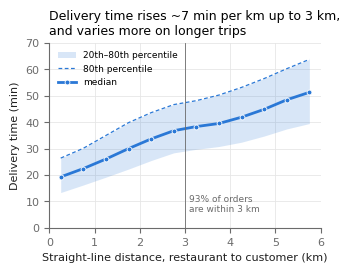

Spearman rho 0.548; slope of medians 7.15 min/km up to 3 km (93.0% of orders), 5.41 min/km beyond
20th-80th percentile spread: 13.0 min at 0-0.5 km -> 24.3 min at 5.5-6 km


dist_haversine_km,"(0.0, 0.5]","(0.5, 1.0]","(1.0, 1.5]","(1.5, 2.0]","(2.0, 2.5]","(2.5, 3.0]","(3.0, 3.5]","(3.5, 4.0]","(4.0, 4.5]","(4.5, 5.0]","(5.0, 5.5]","(5.5, 6.0]"
0.2,13.3,16.2,19.2,22.2,25.4,28.4,29.7,30.8,32.4,34.7,37.4,39.5
0.5,19.2,22.4,26.0,30.0,33.6,36.8,38.3,39.5,41.9,44.8,48.5,51.3
0.8,26.4,30.1,35.0,39.8,43.6,46.6,48.1,50.2,53.2,56.5,60.2,63.8
orders,61928.0,103964.0,116508.0,100119.0,77567.0,48049.0,18172.0,8089.0,4346.0,2464.0,1686.0,1287.0


In [3]:
rho = spearmanr(t["dist_haversine_km"], t["delivery_min"]).correlation
bins = np.arange(0, 6.5, 0.5)
b = pd.cut(t["dist_haversine_km"], bins)
q = t.groupby(b, observed=True)["delivery_min"].quantile([0.2, 0.5, 0.8]).unstack()
binned = q[0.5]
centres = np.array([iv.mid for iv in binned.index])
NEAR_KM = 3


def slope_per_km(medians, mids):
    """Least-squares slope through bin medians up to NEAR_KM: the one slope estimator in §2 and §3."""
    near = np.asarray(mids) < NEAR_KM
    return np.polyfit(np.asarray(mids)[near], np.asarray(medians)[near], 1)[0]


slope_near = slope_per_km(binned.values, centres)
slope_far = np.polyfit(centres[centres > NEAR_KM], binned.values[centres > NEAR_KM], 1)[0]
share_near = (t["dist_haversine_km"] <= NEAR_KM).mean()
spread = q[0.8] - q[0.2]

fig, ax = plt.subplots(figsize=(COL1, 2.4))
ax.fill_between(centres, q[0.2], q[0.8], color=BLUE, alpha=0.18, lw=0, label="20th–80th percentile")
ax.plot(centres, q[0.8], color=BLUE, lw=0.9, ls=(0, (3, 2)), label="80th percentile")
ax.plot(centres, binned.values, color=BLUE, lw=2, marker="o", ms=3.5, mec="white", mew=0.6, label="median")
ax.axvline(NEAR_KM, color=MUTED, lw=0.6)
ax.text(NEAR_KM + 0.08, 6, f"{share_near:.0%} of orders\nare within {NEAR_KM} km", fontsize=6.5, color=MUTED)
ax.set_xlim(0, 6); ax.set_ylim(0, 70)
ax.set_xlabel("Straight-line distance, restaurant to customer (km)"); ax.set_ylabel("Delivery time (min)")
grid(ax, "both"); ax.legend(frameon=False, fontsize=6.5, loc="upper left")
ax.set_title(f"Delivery time rises ~{slope_near:.0f} min per km up to {NEAR_KM} km,\nand varies more on longer trips")
save(fig, "delivery_vs_distance")
plt.show()
print(f"Spearman rho {rho:.3f}; slope of medians {slope_near:.2f} min/km up to {NEAR_KM} km ({share_near:.1%} of orders), "
      f"{slope_far:.2f} min/km beyond")
print(f"20th-80th percentile spread: {spread.iloc[0]:.1f} min at 0-0.5 km -> {spread.iloc[-1]:.1f} min at 5.5-6 km")
q.round(1).assign(orders=t.groupby(b, observed=True).size()).T

**Reading:** distance is the strongest single driver (Spearman 0.55). The median rises about 7.2 min per km up to
3 km (19.2 → 36.8 min) and about 5.4 min per km after that. (v0 said "about 6", the slope from the first bin to
the last.) The spread grows too: the 20th–80th percentile gap goes from 13.0 min under 0.5 km to 24.3 min at
5.5–6 km. This is a relationship, not a cause; long trips also differ by area and hour.

**Informs:** distance stays the core feature (F1). Because the spread grows with distance, an 80% promise needs
more margin on long trips, which is the case for the q80 model (L4). Expect bigger errors on long trips (M6).

## 3. Simpson check: does distance hold within every area? (Lec 4) [report]
Areas differ in trip length, so area could hide or fake the distance effect. One small panel per area, same axes.

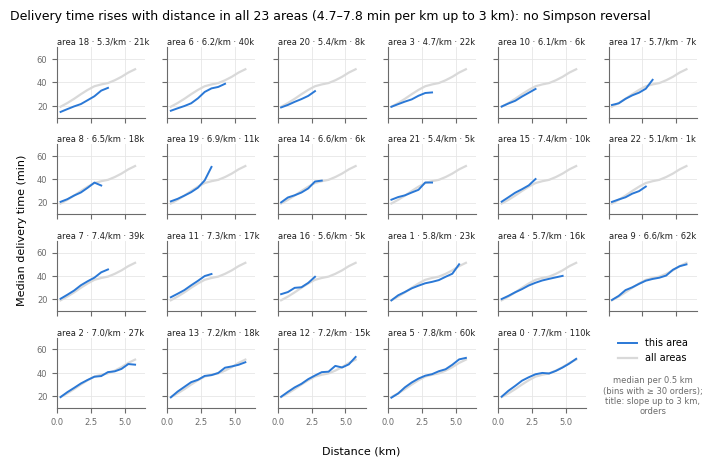

area median time vs area median distance: Spearman 0.79
spread of area medians (order-weighted SD): 4.1 min raw, 2.4 min after distance -> distance accounts for 67% of the variance between areas
range: 13.7 min raw; after distance -6.2 (area 18) to +4.0 (area 16)
slopes up to 3 km: 4.7 to 7.8 min/km (pooled 7.2)


,orders,median_min,median_km,after_distance
district,,,,
18,20872,18.97,1.04,-6.17
6,40222,20.05,1.10,-5.38
20,7584,22.86,1.10,-2.37
0,110289,32.68,1.87,2.22
11,16588,27.57,1.14,2.32
16,5065,28.10,1.03,3.97


In [4]:
pooled = binned
areas = t.groupby("district")["delivery_min"].median().sort_values().index
slopes = {}
fig, axes = plt.subplots(4, 6, figsize=(COL2, 4.6), sharex=True, sharey=True)
for ax, a in zip(axes.flat, areas):
    dd = t[t["district"] == a]
    m = dd.groupby(pd.cut(dd["dist_haversine_km"], bins), observed=True)["delivery_min"].agg(["median", "size"])
    m = m[m["size"] >= 30]
    mids = [iv.mid for iv in m.index]
    slopes[a] = slope_per_km(m["median"], mids)
    ax.plot(centres, pooled.values, color=LIGHT, lw=1.6)
    ax.plot(mids, m["median"], color=BLUE, lw=1.4)
    ax.set_title(f"area {a} · {slopes[a]:.1f}/km · {len(dd) / 1000:.0f}k", fontsize=6, color=INK, pad=2)
    ax.tick_params(labelsize=6); grid(ax, "both")
leg = axes.flat[-1]; leg.axis("off")
leg.plot([], [], color=BLUE, lw=1.4, label="this area"); leg.plot([], [], color=LIGHT, lw=1.6, label="all areas")
leg.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), frameon=False, fontsize=7)
leg.text(0.5, -0.12, "median per 0.5 km\n(bins with ≥ 30 orders);\ntitle: slope up to 3 km,\norders", ha="center",
         va="bottom", fontsize=6, color=MUTED, transform=leg.transAxes)
axes[0, 0].set_xlim(0, 6.5); axes[0, 0].set_ylim(10, 70)
fig.supxlabel("Distance (km)", fontsize=8); fig.supylabel("Median delivery time (min)", fontsize=8)
fig.suptitle(f"Delivery time rises with distance in all {len(areas)} areas ({min(slopes.values()):.1f}–{max(slopes.values()):.1f} "
             "min per km up to 3 km): no Simpson reversal", x=0.01, ha="left", fontsize=9)
fig.tight_layout()
save(fig, "distance_by_area")
plt.show()

# How much of the gap between areas is distance? Adjust each order by the median for its distance (0.25-km bins)
kb = pd.cut(t["dist_haversine_km"].clip(upper=8), np.arange(0, 8.25, 0.25), include_lowest=True)
t["after_distance"] = t["delivery_min"] - t.groupby(kb, observed=True)["delivery_min"].transform("median")
area = t.groupby("district").agg(orders=("order_id", "size"), median_min=("delivery_min", "median"),
                                 median_km=("dist_haversine_km", "median"), after_distance=("after_distance", "median"))
w = area["orders"] / area["orders"].sum()


def weighted_sd(x):
    return np.sqrt((w * (x - (w * x).sum()) ** 2).sum())


sd_raw, sd_adj = weighted_sd(area["median_min"]), weighted_sd(area["after_distance"])
print(f"area median time vs area median distance: Spearman {spearmanr(area['median_min'], area['median_km']).correlation:.2f}")
print(f"spread of area medians (order-weighted SD): {sd_raw:.1f} min raw, {sd_adj:.1f} min after distance "
      f"-> distance accounts for {1 - (sd_adj / sd_raw) ** 2:.0%} of the variance between areas")
print(f"range: {area['median_min'].max() - area['median_min'].min():.1f} min raw; after distance "
      f"{area['after_distance'].min():+.1f} (area {area['after_distance'].idxmin()}) to "
      f"{area['after_distance'].max():+.1f} (area {area['after_distance'].idxmax()})")
print(f"slopes up to 3 km: {min(slopes.values()):.1f} to {max(slopes.values()):.1f} min/km (pooled {slope_near:.1f})")
area.sort_values("after_distance").round(2).iloc[[0, 1, 2, -3, -2, -1]]

**Reading:** delivery time rises with distance in all 23 areas, at 4.7–7.8 min per km up to 3 km (pooled 7.2).
No reversal. The panels also show why areas differ: fast areas mostly do short trips (median about 1.0–1.1 km),
slow ones go out to 5–6 km (median 1.7–1.9 km). Distance explains about two-thirds of the variance between area
medians (weighted SD 4.1 → 2.4 min). The rest is real: after adjusting for distance, areas still span 10 min,
from −6.2 (area 18) and −5.4 (area 6) to +4.0 (area 16).

**Informs:** keep area one-hot (F7) for the part distance doesn't explain. Areas 18 and 6 (61,000 orders) are
fast even at the same distance, which is worth a sentence in the report.

## 4. Late rate by area × hour (Lec 4) [report]
*Late* = after the platform's promise. The promise is never under 30 min (§5), so short-trip areas are rarely
late. The orange bars show each area's share of 30-min promises.

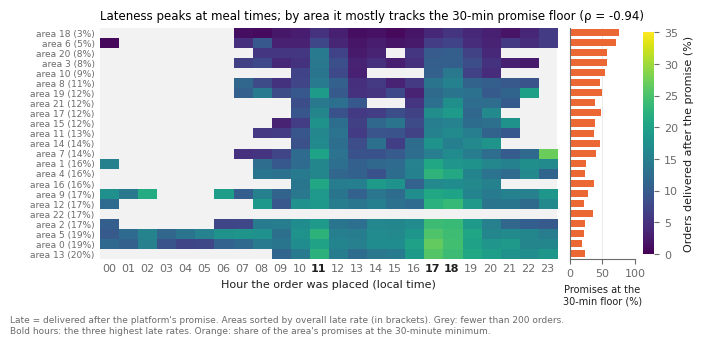

late rate by hour (%): {0: 10.9, 1: 11.3, 2: 16.0, 3: 10.8, 4: 10.1, 5: 11.9, 6: 13.6, 7: 10.0, 8: 11.4, 9: 9.2, 10: 12.6, 11: 17.6, 12: 12.3, 13: 9.7, 14: 11.2, 15: 11.1, 16: 13.3, 17: 19.3, 18: 18.7, 19: 15.4, 20: 13.4, 21: 13.7, 22: 13.6, 23: 14.7}
overall 14.8%; by area 3.5% (area 18) to 19.6% (area 13); cells hidden (< 200 orders): 136
area late rate vs share at the floor: Spearman -0.94; vs area median delivery time: 0.94
share at the floor, areas 18 and 6: {18: 76.0, 6: 71.0} | late rate at the floor vs above it: 8.5% vs 18.1%
top 3 late hours, training days only: [17, 18, 11]


In [5]:
late = t.pivot_table(index="district", columns="hour", values="late", aggfunc="mean")
n = t.pivot_table(index="district", columns="hour", values="late", aggfunc="size")
order = t.groupby("district")["late"].mean().sort_values().index      # lowest late rate on top
MIN_N = 200                                                             # smaller cells are too noisy to colour
shown = (late.where(n >= MIN_N) * 100).loc[order]
by_hour = t.groupby("hour")["late"].mean() * 100
by_area = t.groupby("district")["late"].mean() * 100
t["at_floor"] = t["promise_min"] < 30.5                               # the 30-minute minimum promise (§5)
floor = t.groupby("district")["at_floor"].mean() * 100
top3 = by_hour.nlargest(3).index
rho_floor = spearmanr(by_area, floor).correlation

fig, (ax, fx) = plt.subplots(1, 2, figsize=(COL2, 3.0), sharey=True, gridspec_kw={"width_ratios": [7, 1], "wspace": 0.05})
ax.set_facecolor("#f2f2f2")
im = ax.imshow(shown.values, aspect="auto", cmap="viridis", vmin=0, vmax=35)
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)])
for lab, h in zip(ax.get_xticklabels(), range(24)):
    if h in top3:
        lab.set_fontweight("bold"); lab.set_color(INK)
ax.set_yticks(range(len(order)), [f"area {a} ({by_area[a]:.0f}%)" for a in order], fontsize=6.5)
ax.set_xlabel("Hour the order was placed (local time)")
ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
fx.barh(range(len(order)), floor.loc[order].values, color=ORANGE, height=0.7)
fx.set_xlim(0, 100); fx.set_xticks([0, 50, 100]); fx.set_xlabel("Promises at the\n30-min floor (%)", fontsize=7)
fx.tick_params(axis="y", length=0); grid(fx, "x")
cb = fig.colorbar(im, ax=[ax, fx], fraction=0.02, pad=0.015)
cb.set_label("Orders delivered after the promise (%)"); cb.outline.set_visible(False)
ax.set_title(f"Lateness peaks at meal times; by area it mostly tracks the 30-min promise floor (ρ = {rho_floor:.2f})",
             fontsize=8.5)
fig.text(0.0, -0.08, f"Late = delivered after the platform's promise. Areas sorted by overall late rate (in brackets). Grey: fewer "
         f"than {MIN_N} orders.\nBold hours: the three highest late rates. Orange: share of the area's promises at the "
         "30-minute minimum.", fontsize=6.5, color=MUTED, va="top")
save(fig, "late_rate_area_hour")
plt.show()
print("late rate by hour (%):", by_hour.round(1).to_dict())
print(f"overall {t['late'].mean():.1%}; by area {by_area.min():.1f}% (area {by_area.idxmin()}) to {by_area.max():.1f}% "
      f"(area {by_area.idxmax()}); cells hidden (< {MIN_N} orders): {int(((n < MIN_N) & n.notna()).sum().sum())}")
print(f"area late rate vs share at the floor: Spearman {rho_floor:.2f}; vs area median delivery time: "
      f"{spearmanr(by_area, t.groupby('district')['delivery_min'].median()).correlation:.2f}")
print("share at the floor, areas 18 and 6:", floor.loc[[18, 6]].round(0).to_dict(), "| late rate at the floor vs above it: "
      f"{t.loc[t['at_floor'], 'late'].mean():.1%} vs {t.loc[~t['at_floor'], 'late'].mean():.1%}")
print("top 3 late hours, training days only:", list((t[t["day"] <= 20221022].groupby("hour")["late"].mean()).nlargest(3).index))

**Reading:** 14.8% of orders are late. By hour it peaks at 17:00 (19.3%), 18:00 (18.7%) and 11:00 (17.6%),
against 9–10% mid-morning and mid-afternoon; the training days alone give the same three hours. By area it runs
from 3.5% (area 18) to 19.6% (area 13), but that's mostly the floor. A third of promises sit at 30 min, and those
orders are late far less often (8.5% vs 18.1%). The areas that are rarely late have the most floor promises (76%
in area 18; Spearman −0.94). Fast areas look punctual because 30 minutes is generous for short trips. Cells with
under 200 orders are grey.

**Informs:** report L4 and M6 results by hour and area, but compare areas on minutes of error, not late rate.

## 5. How good is the platform's promise? (Lec 3) [report, slides]
Left: how the promise is set. Right: how arrivals compare with it.

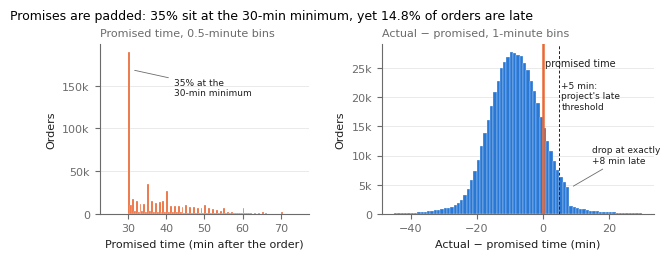

median gap -8.3 min; late 14.8%; late > 5 min 4.8%; early by > 10 min 41.3%; not shown: promises over 75 min 0.4%, gaps outside -45...+30 min 0.2%
share of promises at the floor by distance: {Interval(0, 1, closed='right'): 0.65, Interval(1, 2, closed='right'): 0.35, Interval(2, 3, closed='right'): 0.05, Interval(3, 20, closed='right'): 0.0}


In [6]:
from common.config import LATE_THRESHOLD_MIN

gm, p = t["gap_min"], t["promise_min"]
thousands = plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k" if v else "0")
fig, (pa, ga) = plt.subplots(1, 2, figsize=(COL2, 2.2), gridspec_kw={"width_ratios": [1, 1.3]})
pa.hist(p[p <= 75], bins=np.arange(25, 75.5, 0.5), color=ORANGE, edgecolor="white", lw=0.2)
pa.annotate(f"{t['at_floor'].mean():.0%} at the\n30-min minimum", xy=(31, pa.get_ylim()[1] * 0.85),
            xytext=(42, pa.get_ylim()[1] * 0.7), fontsize=6.5, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
pa.set_xlabel("Promised time (min after the order)"); pa.set_ylabel("Orders")
pa.set_title("Promised time, 0.5-minute bins", fontsize=8, color=MUTED)
inside = gm.between(-45, 30)
ga.hist(gm[inside], bins=np.arange(-45, 31, 1), color=BLUE, edgecolor="white", lw=0.2)
top = ga.get_ylim()[1]
ga.axvline(0, color=ORANGE, lw=1.8); ga.text(0.8, top * 0.92, "promised time", fontsize=7, color=INK, va="top")
ga.axvline(LATE_THRESHOLD_MIN, color=INK, lw=0.7, ls=(0, (3, 2)))
ga.text(LATE_THRESHOLD_MIN + 0.6, top * 0.62, f"+{LATE_THRESHOLD_MIN} min:\nproject's late\nthreshold", fontsize=6.5, color=INK)
ga.annotate("drop at exactly\n+8 min late", xy=(8.5, 4500), xytext=(15, top * 0.3), fontsize=6.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
ga.set_xlabel("Actual − promised time (min)"); ga.set_ylabel("Orders")
ga.set_title("Actual − promised, 1-minute bins", fontsize=8, color=MUTED)
for ax in (pa, ga):
    grid(ax); ax.yaxis.set_major_formatter(thousands)
fig.subplots_adjust(wspace=0.3)
fig.suptitle(f"Promises are padded: {t['at_floor'].mean():.0%} sit at the 30-min minimum, "
             f"yet {t['late'].mean():.1%} of orders are late", x=0.0, ha="left", fontsize=9, y=1.04)
save(fig, "promise_gap")
plt.show()
print(f"median gap {gm.median():.1f} min; late {(gm > 0).mean():.1%}; late > 5 min {(gm > 5).mean():.1%}; "
      f"early by > 10 min {(gm < -10).mean():.1%}; not shown: promises over 75 min {(p > 75).mean():.1%}, "
      f"gaps outside -45...+30 min {1 - inside.mean():.1%}")
print("share of promises at the floor by distance:", t.groupby(pd.cut(t["dist_haversine_km"], [0, 1, 2, 3, 20]), observed=True)
      ["at_floor"].mean().round(2).to_dict())

In [7]:
# The +8-minute cliff: how sharp is it, and is it the same at every promise level?
gs = gm * 60
print("orders per 15 s, 7:00 to 9:00 min late:")
print(pd.cut(gs, np.arange(420, 541, 15), right=False).value_counts().sort_index().to_frame("orders").T.to_string())
print("late rate at each threshold:", {f"> {k} min": f"{(gm > k).mean():.2%}" for k in (0, 5, 8, 10)})
t["promise_band"] = pd.cut(p, [0, 30.5, 36, 40, 45, 60, 1e4], labels=["floor (30)", "30.5–36", "36–40", "40–45", "45–60", "60+"])
cliff = t.groupby("promise_band", observed=True)["gap_min"].agg(
    orders="size", late_7_8=lambda s: ((s >= 7) & (s < 8)).sum(), late_8_9=lambda s: ((s >= 8) & (s < 9)).sum())
cliff["ratio"] = cliff["late_7_8"] / cliff["late_8_9"]
cliff.round(1)

orders per 15 s, 7:00 to 9:00 min late:
gap_min  [420, 435)  [435, 450)  [450, 465)  [465, 480)  [480, 495)  [495, 510)  [510, 525)  [525, 540)
orders         1241        1230        1051        1054         448         344         312         295
late rate at each threshold: {'> 0 min': '14.77%', '> 5 min': '4.84%', '> 8 min': '1.86%', '> 10 min': '1.41%'}


,orders,late_7_8,late_8_9,ratio
promise_band,,,,
floor (30),189914,629,238,2.6
30.5–36,110894,826,285,2.9
36–40,62182,730,192,3.8
40–45,70021,852,259,3.3
45–60,94446,1382,355,3.9
60+,18883,157,70,2.2


**Reading:** the promise is padded. 34.6% of promises are the 30-min minimum (65% of trips under 1 km, almost
none over 3 km), and above that it moves in rounded steps (spikes at 35, 40, 50 and 60). The median order arrives
8.3 min early and 41.3% arrive more than 10 min early, yet 14.8% are late.

There's a cliff at exactly +8 min. Counts fall steadily, then drop by more than half within seconds of 8:00
(1,054 orders in the 15 s before, 448 in the 15 s after). It happens at every promise level, with 2.2–3.9 times
as many orders 7–8 min late as 8–9. That looks like an operational rule, but we can't tell which one. If late
orders get their promise extended or their arrival logged early, part of the promise is after-order information.

**Informs:** (1) don't compare ETA models with the promise on MAE alone; L4 compares them at the same mean
promise. (2) L4's 5- and 10-min thresholds sit on either side of the cliff (4.8% vs 1.4% late), so report both
and say why. (3) The limitations should say the promise may not be pure order-time information.

## 6. Orders without a usable prep estimate: really slower? (Lec 3) [notebook]
Two codes mean no estimate: a stored 0 (C2) and a default under 5 min (C2b). Is their extra delivery time the
missing estimate, or something else?

In [8]:
t["dist_band"] = pd.cut(t["dist_haversine_km"], [0, 1, 2, 3, 4, 20], labels=["0–1", "1–2", "2–3", "3–4", "4+"])
t["prep_group"] = np.select([t["prep_default"] == 1, t["prep_missing"] == 1], ["default (< 5 min)", "stored as 0"],
                            "real estimate")
prep_groups = ["real estimate", "default (< 5 min)", "stored as 0"]
print("orders:", t["prep_group"].value_counts()[prep_groups].to_dict())
print("median distance (km):", t.groupby("prep_group")["dist_haversine_km"].median()[prep_groups].round(2).to_dict())
tab = t.pivot_table(index="dist_band", columns="prep_group", values="delivery_min", aggfunc="median", observed=True)[prep_groups]
for g in prep_groups[1:]:
    tab[f"{g} − real"] = tab[g] - tab["real estimate"]
tab.round(1)

orders: {'real estimate': 463540, 'default (< 5 min)': 75361, 'stored as 0': 7439}
median distance (km): {'real estimate': 1.39, 'default (< 5 min)': 1.8, 'stored as 0': 2.83}


prep_group,real estimate,default (< 5 min),stored as 0,default (< 5 min) − real,stored as 0 − real
dist_band,,,,,
0–1,21.0,23.8,23.4,2.8,2.4
1–2,27.1,32.1,30.4,5.0,3.3
2–3,34.3,36.7,37.0,2.4,2.7
3–4,38.1,40.1,42.0,2.0,3.9
4+,46.7,46.2,50.3,-0.5,3.6


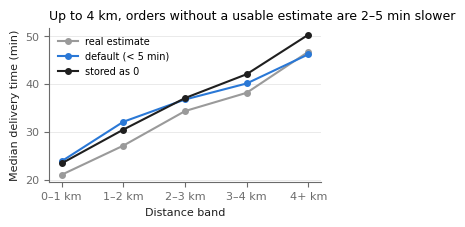

In [9]:
fig, ax = plt.subplots(figsize=(COL1, 2.0))
x = np.arange(len(tab))
for g, c in zip(prep_groups, [GREY, BLUE, INK]):
    ax.plot(x, tab[g], "o-", color=c, lw=1.5, ms=4, label=g)
ax.set_xticks(x, [f"{b} km" for b in tab.index]); ax.set_ylabel("Median delivery time (min)")
ax.set_xlabel("Distance band"); grid(ax); ax.legend(frameon=False, fontsize=7)
gaps = tab[[f"{g} − real" for g in prep_groups[1:]]].drop(index="4+")      # few orders beyond 4 km
ax.set_title(f"Up to 4 km, orders without a usable estimate are {gaps.min().min():.0f}–{gaps.max().max():.0f} min slower")
plt.show()

**Reading:** 15% of orders have no usable estimate (75,361 defaults, 7,439 zeros). Both groups are longer trips
(median 1.80 and 2.83 km vs 1.39), which explains part of it. At the same distance they're still slower up to
4 km: defaults by 2.0–5.0 min, zeros by 2.4–3.9 min. So missingness carries a few minutes of signal.

**Informs:** keep median imputation (C6) and both flags (F3, C2b). A sentence in the report, not a figure.

## 7. Load: a busy area, or just a big area at a busy hour? (Lec 4) [notebook]
`load_15m` = orders in the same area in the last 15 min. It's highest at meal peaks and in the biggest areas,
which are also the slowest. So how much does load matter once area and hour are held fixed? Same check for
`load_15m_rel` (load relative to the area's last 24 h, missing on day 1).

areas behind the busiest fifth of load_15m (% of those orders): {0: 62.0, 9: 19.0, 5: 14.0}
area size vs area median load: Spearman 1.00


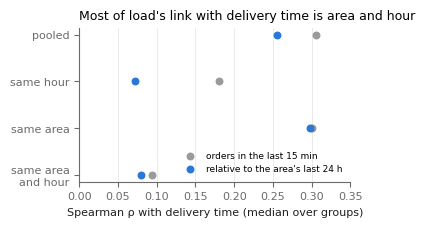

,load_15m,load_15m_rel
pooled,0.30,0.26
same hour,0.18,0.07
same area,0.30,0.30
same area\nand hour,0.09,0.08


In [10]:
def rho(dd, col):
    return spearmanr(dd[col], dd["delivery_min"], nan_policy="omit").correlation

big_cells = t.groupby(["district", "hour"]).filter(lambda dd: len(dd) >= 200)     # area x hour cells with >= 200 orders
levels = {"pooled": lambda col: rho(t, col),
          "same hour": lambda col: t.groupby("hour").apply(rho, col, include_groups=False).median(),
          "same area": lambda col: t.groupby("district").apply(rho, col, include_groups=False).median(),
          "same area\nand hour": lambda col: big_cells.groupby(["district", "hour"]).apply(rho, col, include_groups=False).median()}
lr = pd.DataFrame({col: {k: f(col) for k, f in levels.items()} for col in ["load_15m", "load_15m_rel"]})
top = t["load_15m"] > t["load_15m"].quantile(0.8)
print("areas behind the busiest fifth of load_15m (% of those orders):",
      (t.loc[top, "district"].value_counts(normalize=True).head(3) * 100).round(0).to_dict())
print(f"area size vs area median load: Spearman {spearmanr(t.groupby('district').size(), t.groupby('district')['load_15m'].median()).correlation:.2f}")

fig, ax = plt.subplots(figsize=(COL1, 2.0))
y = np.arange(len(lr))
ax.scatter(lr["load_15m"], y, color=GREY, s=22, label="orders in the last 15 min", zorder=3)
ax.scatter(lr["load_15m_rel"], y, color=BLUE, s=22, label="relative to the area's last 24 h", zorder=3)
ax.set_yticks(y, lr.index); ax.invert_yaxis(); ax.set_xlim(0, 0.35)
ax.set_xlabel("Spearman ρ with delivery time (median over groups)"); grid(ax, "x")
ax.legend(frameon=False, fontsize=6.5, loc="lower right")
ax.set_title("Most of load's link with delivery time is area and hour")
plt.show()
lr.round(2)

**Reading:** load looks important mostly because of where and when it's high. Area size and area load rank
identically (Spearman 1.00), and 95% of the busiest fifth of orders come from areas 0, 9 and 5, which are among
the slowest. Pooled, load correlates 0.30 with delivery time; within the same hour 0.18; within the same area and
hour only 0.09. In a given area at a given hour, a busier 15 minutes barely matters. Relative load is similar
(0.08) and mostly reflects time of day.

**Informs (F6):** we keep load as `load_15m_rel`, so big areas don't look busy just for being big. On CV it beats
the raw count by 0.021 (Elastic-Net) and 0.009 min (boosting); dropping load entirely costs only 0.04 and 0.005.
The proposal expected load to be a top driver. That now looks unlikely, and M5 should check it.

## 8. Does the restaurant's prep estimate predict delivery time? [notebook]

Spearman prep estimate vs delivery, real estimates (85% of orders): 0.24; within distance bands 0.04 to 0.35


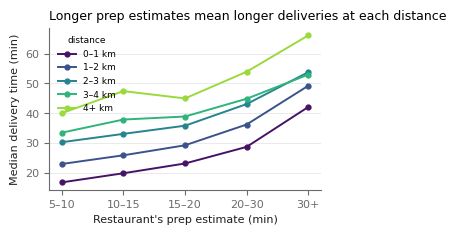

dist_band,0–1,1–2,2–3,3–4,4+,orders
prep_band,,,,,,
5–10,16.8,22.9,30.2,33.4,40.0,57846
10–15,19.8,25.8,33.0,37.9,47.4,247161
15–20,23.1,29.2,35.8,38.9,45.0,126198
20–30,28.7,36.2,43.1,44.9,53.9,30539
30+,42.1,49.2,53.8,53.0,66.2,1796


In [11]:
pm = t["prep_min"].notna()      # real estimates only: stored zeros (C2) and defaults under 5 min (C2b) are missing
within = t[pm].groupby("dist_band", observed=True).apply(
    lambda dd: spearmanr(dd["prep_min"], dd["delivery_min"]).correlation, include_groups=False)
print(f"Spearman prep estimate vs delivery, real estimates ({pm.mean():.0%} of orders): "
      f"{spearmanr(t.loc[pm, 'prep_min'], t.loc[pm, 'delivery_min']).correlation:.2f}; "
      f"within distance bands {within.min():.2f} to {within.max():.2f}")
t["prep_band"] = pd.cut(t["prep_min"], [5, 10, 15, 20, 30, 75], labels=["5–10", "10–15", "15–20", "20–30", "30+"],
                       include_lowest=True)
pt = t.pivot_table(index="prep_band", columns="dist_band", values="delivery_min", aggfunc="median", observed=True)
fig, ax = plt.subplots(figsize=(COL1, 2.1))
for (band, col), c in zip(pt.items(), plt.cm.viridis(np.linspace(0.05, 0.85, pt.shape[1]))):
    ax.plot(range(len(pt)), col, "o-", color=c, lw=1.4, ms=3.5, label=f"{band} km")
ax.set_xticks(range(len(pt)), [str(b) for b in pt.index]); ax.set_xlabel("Restaurant's prep estimate (min)")
ax.set_ylabel("Median delivery time (min)"); grid(ax)
ax.legend(title="distance", frameon=False, fontsize=6.5, title_fontsize=6.5, loc="upper left")
ax.set_title("Longer prep estimates mean longer deliveries at each distance")
plt.show()
pt.round(1).assign(orders=t.groupby("prep_band", observed=True).size())

**Reading:** with the defaults set aside, the prep estimate does matter: Spearman 0.24 on the 85% of orders with a
real estimate (0.08 before). It isn't just distance. Within each distance band, longer estimates mean longer
deliveries (16.8 → 28.7 min from 5–10 to 20–30 min estimates, for trips under 1 km). The link weakens on longer
trips (0.35 under 1 km, 0.04 over 4 km) as the ride takes over.

**Informs (S4):** the v0 "U-shape" was the defaults (now C2b). `prep_min` stays an input (F2) with both flags
(F3).

## 9. Delivery time and order volume by hour (Lec 4) [report]
The proposal promised this, and the peak flags (F5) need it. Training days only, since it sets a feature.

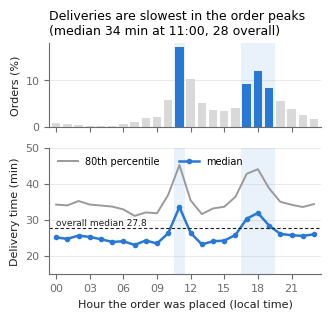

hours slower than the overall median, training days: [11, 17, 18, 19] | test days: [11, 17, 18]


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
orders,3553.0,2293.0,1477.0,941.0,649.0,641.0,2170.0,4393.0,7234.0,8294.0,...,14815.0,13442.0,16275.0,37585.0,48965.0,34074.0,22302.0,15094.0,9900.0,6569.0
median,25.1,24.7,25.6,25.2,24.6,23.8,24.0,23.0,24.2,23.4,...,24.0,24.2,25.8,30.3,31.9,28.4,26.1,25.7,25.5,26.0
p80,34.2,34.0,35.2,34.2,33.9,33.6,32.9,31.1,32.0,31.8,...,33.1,33.6,36.4,42.8,44.0,38.7,35.0,34.2,33.5,34.3
share,0.9,0.6,0.4,0.2,0.2,0.2,0.5,1.1,1.8,2.0,...,3.6,3.3,4.0,9.2,12.0,8.4,5.5,3.7,2.4,1.6


In [12]:
tr = t[t["day"] <= 20221022]
overall = tr["delivery_min"].median()
hp = tr.groupby("hour").agg(orders=("order_id", "size"), median=("delivery_min", "median"),
                            p80=("delivery_min", lambda s: s.quantile(.8)))
hp["share"] = hp["orders"] / hp["orders"].sum() * 100
peak = list(hp.index[hp["median"] > overall])      # rule: hours slower than the overall median

fig, (top, bottom) = plt.subplots(2, 1, figsize=(COL1, 3.0), sharex=True, gridspec_kw={"height_ratios": [1, 1.5]})
for ax in (top, bottom):
    for h in peak:
        ax.axvspan(h - 0.5, h + 0.5, color=BLUE, alpha=0.10, lw=0)
top.bar(hp.index, hp["share"], color=[BLUE if h in peak else LIGHT for h in hp.index], width=0.75)
top.set_ylabel("Orders (%)"); grid(top)
bottom.plot(hp.index, hp["p80"], color=GREY, lw=1.4, label="80th percentile")
bottom.plot(hp.index, hp["median"], color=BLUE, lw=1.8, marker="o", ms=3, label="median")
bottom.axhline(overall, color=INK, lw=0.8, ls=(0, (3, 2)))
bottom.text(0, overall + 0.6, f"overall median {overall:.1f}", fontsize=6.5, color=INK)
bottom.set_ylim(15, 50); bottom.set_ylabel("Delivery time (min)")
bottom.set_xticks(range(0, 24, 3), [f"{h:02d}" for h in range(0, 24, 3)]); bottom.set_xlim(-0.6, 23.6)
bottom.set_xlabel("Hour the order was placed (local time)"); grid(bottom)
bottom.legend(frameon=False, fontsize=7, loc="upper left", ncol=2)
top.set_title(f"Deliveries are slowest in the order peaks\n(median {hp.loc[11, 'median']:.0f} min at 11:00, {overall:.0f} overall)")
save(fig, "delivery_by_hour")
plt.show()

te = t[t["day"] > 20221022]
te_med = te.groupby("hour")["delivery_min"].median()
print("hours slower than the overall median, training days:", peak,
      "| test days:", list(te_med.index[te_med > te["delivery_min"].median()]))
hp.round(1).T

**Reading:** volume and delivery time peak together. 11:00 has 17% of training orders and a median of 33.5 min
(27.8 overall), while 10:00 and 12:00 are busy but normal (26.3). 17:00–19:00 have 30% of orders and medians of
28.4–31.9. Those four hours are exactly the ones above the overall median. The test days pick 11, 17 and 18, with
19 just under. The 80th percentile follows the same shape.

**Informs (F5):** `lunch_peak` is now 11:00 only; `dinner_peak` stays 17–19. Of four options tried on CV, this
one cut Elastic-Net MAE by 0.07 min. Boosting didn't change, since it already learns hours from `tod_sin` and
`tod_cos`.

## 10. Days and the weekend (Lec 3) [report]
`is_weekend` isn't a model input (F8), so the weekend is described here instead. Weekend = Sat 22 and Sun 23 by
`dt`. All eight days are shown, because the point is how the test days differ.

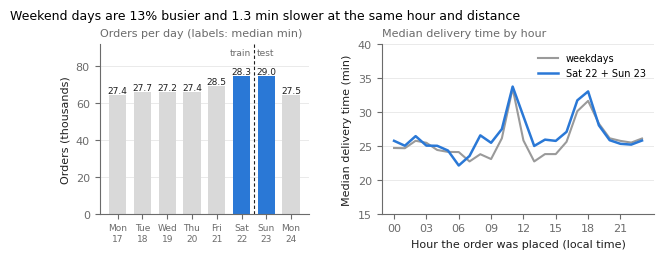

same hour and distance band, weekend minus weekday median: +1.30 min; Sun 23 share of test orders: 54%
median by hour, weekdays vs weekend (11-13): {11: {False: 33.5, True: 33.8}, 12: {False: 25.8, True: 29.4}, 13: {False: 22.7, True: 25.0}}


,orders,median,p90,late
day,,,,
20221017,64291,27.4,45.4,13.1
20221018,66300,27.7,45.4,15.4
20221019,65863,27.2,44.6,14.6
20221020,65981,27.4,44.7,14.4
20221021,69270,28.5,46.8,15.7
20221022,74848,28.3,46.2,14.9
20221023,75063,29.0,47.5,16.4
20221024,64724,27.5,45.2,13.1


In [13]:
WEEKEND = [20221022, 20221023]
t["weekend_day"] = t["day"].isin(WEEKEND)
days = t.groupby("day").agg(orders=("order_id", "size"), median=("delivery_min", "median"),
                            p90=("delivery_min", lambda s: s.quantile(.9)), late=("late", "mean"))
busier = days.loc[WEEKEND, "orders"].mean() / days.drop(WEEKEND)["orders"].mean() - 1
wk = t.pivot_table(index="hour", columns="weekend_day", values="delivery_min", aggfunc="median")
# weekend vs weekday at the same hour and distance band, weighted by weekend orders
t["dist_band4"] = pd.cut(t["dist_haversine_km"], [0, 1, 2, 3, 20])
cell = t.groupby(["hour", "dist_band4", "weekend_day"], observed=True)["delivery_min"].median().unstack()
n_wknd = t[t["weekend_day"]].groupby(["hour", "dist_band4"], observed=True).size()
same_cell_gap = np.average((cell[True] - cell[False]).loc[n_wknd.index], weights=n_wknd)

fig, (a, b) = plt.subplots(1, 2, figsize=(COL2, 2.2), gridspec_kw={"width_ratios": [1, 1.3]})
x = np.arange(len(days))
a.bar(x, days["orders"] / 1000, color=[BLUE if d in WEEKEND else LIGHT for d in days.index], width=0.7)
for xi, (o, md) in enumerate(zip(days["orders"], days["median"])):
    a.text(xi, o / 1000 + 1, f"{md:.1f}", ha="center", fontsize=6.5, color=INK)
a.axvline(5.5, color=INK, lw=0.8, ls=(0, (3, 2)))
a.text(5.4, 86, "train", ha="right", fontsize=6.5, color=MUTED); a.text(5.6, 86, "test", ha="left", fontsize=6.5, color=MUTED)
a.set_xticks(x, [pd.Timestamp(str(d)).strftime("%a\n%d") for d in days.index], fontsize=6.5)
a.set_ylim(0, 92); a.set_ylabel("Orders (thousands)"); grid(a)
a.set_title("Orders per day (labels: median min)", fontsize=8, color=MUTED)
b.plot(wk.index, wk[False], color=GREY, lw=1.5, label="weekdays")
b.plot(wk.index, wk[True], color=BLUE, lw=1.8, label="Sat 22 + Sun 23")
b.set_xticks(range(0, 24, 3), [f"{h:02d}" for h in range(0, 24, 3)]); b.set_xlabel("Hour the order was placed (local time)")
b.set_ylim(15, 40); b.set_ylabel("Median delivery time (min)"); grid(b); b.legend(frameon=False, fontsize=7, loc="upper right")
b.set_title("Median delivery time by hour", fontsize=8, color=MUTED)
fig.subplots_adjust(wspace=0.3)
fig.suptitle(f"Weekend days are {busier:.0%} busier and {same_cell_gap:.1f} min slower at the same hour and distance",
             x=0.0, ha="left", fontsize=9, y=1.04)
save(fig, "weekend_and_days")
plt.show()
print(f"same hour and distance band, weekend minus weekday median: {same_cell_gap:+.2f} min; "
      f"Sun 23 share of test orders: {days.loc[20221023, 'orders'] / days.loc[[20221023, 20221024], 'orders'].sum():.0%}")
print("median by hour, weekdays vs weekend (11-13):", wk.loc[11:13].round(1).to_dict("index"))
days.assign(late=days["late"] * 100).round(1)

**Reading:** the weekend days are the busiest (about 75,000 orders vs 64,000–69,000, +13%) and among the slowest
(median 28.3 Sat and 29.0 Sun, vs 27.2–28.5). At the same hour and distance they're 1.3 min slower, mostly
because lunch runs longer (12:00: 29.4 vs 25.8 min). Friday is already a bit slower (28.5).

**Informs:** the models can't learn this. Sun 23 is the slowest day and 54% of the test set, so expect test errors
above CV errors, especially around 12:00–13:00. M6 should report test errors by day, and the report should list
it as a limitation.

## 11. Do the model features overlap? (Lec 6) [notebook]
Overlap makes Elastic-Net coefficients hard to read (L3) and splits credit in permutation importance (M5). For
each numeric feature: its closest partner, and how much the other features (plus area) predict it. A VIF over
5–10 is the usual warning. Training days, median-imputed like the pipeline.

In [14]:
from common.features import FEATURE_SETS

num = list(FEATURE_SETS["base"].numeric)
tr = t[t["day"] <= 20221022]
X = tr[num].fillna(tr[num].median())
areas = pd.get_dummies(tr["district"], prefix="area", drop_first=True, dtype=float).to_numpy()
corr = X.corr(method="spearman")


def r2(y, Z):
    """Share of y's variance that a linear fit on Z explains."""
    Z = np.column_stack([np.ones(len(Z)), Z])
    beta = np.linalg.lstsq(Z, y, rcond=None)[0]
    return 1 - np.var(y - Z @ beta) / np.var(y)


red = pd.DataFrame({c: {"most related": corr[c].drop(c).abs().idxmax(), "|Spearman|": corr[c].drop(c).abs().max(),
                        "R² from others": r2(X[c].to_numpy(), X.drop(columns=c).to_numpy()),
                        "R² from others + area": r2(X[c].to_numpy(), np.column_stack([X.drop(columns=c).to_numpy(), areas]))}
                    for c in num}).T
for col in ["|Spearman|", "R² from others", "R² from others + area"]:
    red[col] = red[col].astype(float)
red["VIF"] = 1 / (1 - red["R² from others + area"])
TIME = ["tod_sin", "tod_cos", "lunch_peak", "dinner_peak"]
load = X["load_15m_rel"].to_numpy()
print(f"load_15m_rel: R² {r2(load, X[TIME].to_numpy()):.2f} from time of day alone, {r2(load, areas):.2f} from area alone | "
      f"raw load_15m: {r2(tr['load_15m'].to_numpy(), np.column_stack([X[TIME].to_numpy(), areas])):.2f} from time + area")
print(f"dist_haversine_km: R² {r2(X['dist_haversine_km'].to_numpy(), areas):.2f} from area alone")
red.round(2)

load_15m_rel: R² 0.55 from time of day alone, 0.01 from area alone | raw load_15m: 0.72 from time + area
dist_haversine_km: R² 0.13 from area alone


,most related,|Spearman|,R² from others,R² from others + area,VIF
dist_haversine_km,prep_missing,0.15,0.04,0.15,1.17
prep_min,load_15m_rel,0.09,0.02,0.06,1.06
prep_missing,prep_default,0.95,0.90,0.90,9.73
prep_default,prep_missing,0.95,0.90,0.90,9.62
tod_sin,dinner_peak,0.78,0.55,0.56,2.26
tod_cos,lunch_peak,0.55,0.42,0.43,1.75
lunch_peak,tod_cos,0.55,0.57,0.57,2.31
dinner_peak,tod_sin,0.78,0.54,0.54,2.17
load_15m_rel,lunch_peak,0.54,0.55,0.56,2.25


**Reading:** no general problem. Distance and prep barely overlap with anything (VIF 1.2 and 1.1). Two overlaps
are by design: the prep flags are nested, since every default is also missing (VIF 9.7), and the time features
overlap each other (VIF 1.8–2.3). Time of day also explains 55% of `load_15m_rel` (area only 1%), so relative load
is mostly a busy-hour signal. The raw count was worse: time and area explained 72% of it.

**Informs:** M5 should use five groups: distance; prep (`prep_min`, `prep_missing`, `prep_default`); time
(`tod_sin`, `tod_cos`, `lunch_peak`, `dinner_peak`); load; area. It should also permute time and load together,
since each hides the other. In L3, read the two prep flag coefficients together.

## 12. What we looked at (Lec 3: forking paths)
Delivery time against nine variables: distance, area, hour, day, load (raw and relative), prep estimate, missing
prep, and the promise. Within-group checks: distance within areas, load within hour and area, prep within
distance, weekend within hour and distance. Plus the +8 cliff by promise level and the feature overlap. Nothing
else.

On CV (training days only) we tried one prep rule, four peak-hour definitions and four load versions. The peak
hours and the prep rule were picked on training days; everything else is descriptive and uses all eight days.
These are hypotheses for the models, not tested results.

## 13. Conclusion
Distance drives delivery time more than anything else: about 7 min per km up to 3 km (93% of orders), with more
spread on longer trips, and it holds in all 23 areas. Distance explains about two-thirds of the gap between
areas; areas 18 and 6 are still 5–6 min faster at the same distance. Time of day comes next: the slowest hours
are 11:00 (median 33.5 vs 27.8) and 17:00–19:00. Weekends are 13% busier and 1.3 min slower at the same hour and
distance. Load matters much less than it looks (0.09 within area and hour). The prep estimate is useful
(Spearman 0.24) once the 13.8% of defaults are treated as missing, and orders without one are 2–5 min slower at
the same distance.

The promise is padded: 35% sit at the 30-min minimum and the median order is 8.3 min early, yet 14.8% are late.
Late rates by area mostly reflect that minimum, so they aren't a fair way to compare areas. Arrivals drop sharply
at exactly 8 min late, which we can't explain.

**What changed (S4, README §4):** prep under 5 min is missing, with a `prep_default` flag (C2b); `lunch_peak` is
11:00 only (F5); load is `load_15m_rel` (F6). Together: Elastic-Net CV MAE 6.93 → 6.61, boosting 6.284 → 6.279.
Distance and area stay as they are; L3 decides the log target.

**For the team:** M5 uses the five groups in §11 and checks whether load is really a top driver. L4 reports both
late thresholds, knowing the +8 cliff sits between them. M6 reports test errors by day and by distance.